# Q5 — Quy mô sản xuất quốc gia và chất lượng cà phê

| Trường | Nội dung |
| --- | --- |
| Câu hỏi | Ở cấp quốc gia, các nước sản xuất cà phê quy mô nhỏ có điểm chất lượng trung vị cao hơn hay thấp hơn các nước quy mô lớn, và tỷ trọng sản lượng thế giới liên hệ với điểm chất lượng ở mức nào? |
| Loại | non-ML |
| Tiêu chí chiều sâu | D1, D3, D5 |
| Cột dữ liệu sử dụng | `REC_ID`, `Species`, `Country.of.Origin`, `Harvest.Year`, 9 thuộc tính cảm quan của CQI và `Area`, `Year`, `Value` của FAOSTAT |

## 1. Preprocessing

### a. Nguồn dữ liệu và phạm vi

Phân tích kết hợp bảng CQI về điểm từng lô cà phê với FAOSTAT về sản lượng cà phê nhân xanh theo vùng và năm. Bảng CQI giữ tên quốc gia, năm thu hoạch và chín thuộc tính cảm quan. Hàm nạp FAOSTAT chọn ba trường gồm tên vùng, năm và sản lượng tính bằng tấn, đồng thời kiểm tra khóa vùng–năm có đầy đủ và duy nhất.

Đoạn xử lý dưới đây chuẩn bị mẫu Arabica và bỏ bản ghi giữ chỗ 1310. Với mỗi lô, tính `total_9` bằng tổng chín điểm cảm quan trên thang 0–90; nếu thiếu một điểm thì tổng cũng được coi là thiếu. Kết quả là bảng CQI dùng để kiểm tra phép nối và bảng sản lượng tham chiếu. Các lô thiếu năm hoặc nằm ngoài 2010–2017 được giữ ở bước này để có thể theo dõi lý do loại ở các bước sau.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

cwd = Path.cwd()
root = next(path for path in (cwd, *cwd.parents) if (path / "src" / "config.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.config import RAW, add_total_score
from src.merge_external import audit_country_mapping, load_fao, merge_production

cqi = pd.read_csv(RAW / "Coffee_Qlty.csv", keep_default_na=False, na_values=[""])
fao = load_fao()
arabica = cqi.loc[cqi["Species"].eq("Arabica")]
lots = add_total_score(arabica.loc[arabica["REC_ID"].ne(1310)])

### b. Đối chiếu tên quốc gia

Tên quốc gia có thể được ghi khác nhau trong CQI và FAOSTAT, nên cần kiểm tra ánh xạ trước khi nối. Bước này xét toàn bộ nhãn quốc gia CQI, chuẩn hóa cách viết và đối chiếu với danh sách vùng thực sự có trong CSV FAOSTAT. Bảng xuất ra đếm số mục theo trạng thái ánh xạ, gồm tên có dữ liệu tương ứng, tên vắng trong bản trích và mục thiếu tên.

Đây là bảng đếm nhãn quốc gia, mỗi tên đóng góp một mục. Japan có tên tương ứng nhưng vắng trong bản trích sản lượng cà phê. Riêng 16 lô mang nhãn `China` đã được đối chiếu với bản CQI nguồn và đều có địa danh thuộc Yunnan, nên dùng `China, mainland`. Nhãn `Taiwan` được nối riêng tới `China, Taiwan Province of`. Các lựa chọn này giúp điểm của từng nhóm xuất xứ được ghép với đúng phạm vi sản lượng.

In [2]:
country_audit = audit_country_mapping(cqi, fao)
display(
    country_audit["status"].value_counts()
    .rename_axis("Trạng thái ánh xạ")
    .reset_index(name="Số mục")
)

,Trạng thái ánh xạ,Số mục
0,name_matched,33
1,missing_cqi_country,1
2,absent_in_coffee_extract,1


### c. Phép nối và bảng theo dõi số dòng

Mỗi lô CQI được ghép với sản lượng của vùng xuất xứ tại năm thu hoạch của lô đó. Dùng `left join` để giữ mọi lô Arabica trong bảng kiểm tra, kể cả lô chưa tìm được số liệu sản lượng. Nhiều lô có thể cùng trỏ tới một vùng–năm FAOSTAT; phía FAOSTAT phải có tối đa một bản ghi cho khóa này. Điều kiện many-to-one được kiểm tra khi nối để tránh nhân số lô.

Đầu ra gồm bảng số lô trước và sau các bước chuẩn bị, cùng bảng trạng thái phép nối và dữ liệu sản lượng. Điểm cần kiểm tra là số lô trước và sau nối bằng nhau, ở đây là **1.310 lô**. Bảng trạng thái cũng giúp phân biệt lô không khớp khóa với lô đã khớp nhưng giá trị sản lượng bị thiếu, vì hai trường hợp này cần được theo dõi riêng.

In [3]:
merged = merge_production(lots, fao)
assert len(merged) == len(lots)

row_audit = pd.DataFrame(
    [
        ("Chọn Arabica", len(cqi), len(arabica), "Loại Robusta theo phạm vi đã chốt"),
        ("Bỏ REC_ID 1310", len(arabica), len(lots), "Loại bản ghi giữ chỗ"),
        ("Tính total_9", len(lots), len(lots), "Thêm cột tổng điểm cảm quan"),
        ("Left join với FAOSTAT", len(lots), len(merged), "Giữ mọi lô để kiểm tra khóa"),
    ],
    columns=["Thao tác", "Số lô trước", "Số lô sau", "Lý do"],
)
display(row_audit)
display(
    merged.value_counts(["_merge", "status"])
    .rename_axis(["Trạng thái phép nối", "Kết quả audit"])
    .reset_index(name="Số lô")
)

,Thao tác,Số lô trước,Số lô sau,Lý do
0,Chọn Arabica,1339,1311,Loại Robusta theo phạm vi đã chốt
1,Bỏ REC_ID 1310,1311,1310,Loại bản ghi giữ chỗ
2,Tính total_9,1310,1310,Thêm cột tổng điểm cảm quan
3,Left join với FAOSTAT,1310,1310,Giữ mọi lô để kiểm tra khóa


,Trạng thái phép nối,Kết quả audit,Số lô
0,both,candidate_matched,1249
1,left_only,missing_harvest_year,59
2,left_only,missing_cqi_country,1
3,both,matched_key_missing_value,1


### d. Khóa không khớp và ngoại lệ

Tách các lô chưa khớp để kiểm tra nguyên nhân theo tên quốc gia CQI, vùng FAOSTAT và năm thu hoạch. Các khóa có phần bị thiếu vẫn được giữ trong bảng tổng hợp. Bên cạnh đó, kiểm tra xem có khóa đầy đủ nào chưa tìm được bên FAOSTAT hay không. Bảng ngoại lệ thứ hai liệt kê các lô khớp được khóa nhưng thiếu giá trị sản lượng.

Các bảng này giải thích nguồn gốc của dữ liệu chưa dùng được khi xây mẫu phân tích. Với dữ liệu hiện tại, có **60 lô không khớp do thiếu năm**, gồm một lô thiếu cả quốc gia, và không có khóa đầy đủ nào không khớp. Lô Mauritius năm 2016 khớp khóa nhưng thiếu sản lượng. Việc ghi riêng các trường hợp này giúp bước lọc phía sau có lý do và số lượng đối chiếu rõ ràng.

In [4]:
key_columns = ["Country.of.Origin", "country_fao", "year", "status"]
unmatched = merged.loc[merged["_merge"].eq("left_only")]
complete_keys = unmatched.dropna(subset=["country_fao", "year"])
print(f"Số khóa đầy đủ nhưng không khớp: {len(complete_keys[['country_fao', 'year']].drop_duplicates()):,}")
display(unmatched.value_counts(key_columns, dropna=False).reset_index(name="Số lô"))

exceptions = merged.loc[
    merged["_merge"].eq("both") & merged["status"].ne("candidate_matched")
]
display(exceptions.value_counts(key_columns, dropna=False).reset_index(name="Số lô"))

Số khóa đầy đủ nhưng không khớp: 0


,Country.of.Origin,country_fao,year,status,Số lô
0,United States,United States of America,<NA>,missing_harvest_year,19
1,Colombia,Colombia,<NA>,missing_harvest_year,11
2,Brazil,Brazil,<NA>,missing_harvest_year,5
3,Thailand,Thailand,<NA>,missing_harvest_year,5
4,Guatemala,Guatemala,<NA>,missing_harvest_year,4
5,Mexico,Mexico,<NA>,missing_harvest_year,3
6,Nicaragua,Nicaragua,<NA>,missing_harvest_year,3
7,Costa Rica,Costa Rica,<NA>,missing_harvest_year,2
8,Ethiopia,Ethiopia,<NA>,missing_harvest_year,2
9,Kenya,Kenya,<NA>,missing_harvest_year,2


,Country.of.Origin,country_fao,year,status,Số lô
0,Mauritius,Mauritius,2016,matched_key_missing_value,1


### e. Tổng sản lượng thế giới và tỷ trọng theo năm

Để đo quy mô tương đối của từng vùng, lấy sản lượng của vùng chia cho tổng sản lượng thế giới cùng năm. Tổng thế giới lấy trực tiếp từ tám dòng `World` cho 2010–2017. Trước khi chia, kiểm tra mỗi năm có đúng một tổng dương và đầy đủ. Bảng hiển thị dưới đây cho biết các mẫu số được dùng trong phép tính. [Nguồn và bộ lọc FAOSTAT](../data/external/README.md)

Bước này còn tạo bảng `country_year_shares`, mỗi vùng–năm có một dòng sản lượng, tổng thế giới và `production_share`. Tỷ trọng bằng 0,01 tương ứng với 1% sản lượng thế giới. Tạo bảng theo năm trước khi ghép điểm chất lượng giúp mỗi năm có cùng trọng số ở bước lấy trung bình, kể cả năm vùng đó có ít lô CQI. Tử số và mẫu số cùng đo cà phê nhân xanh.

In [5]:
analysis_years = list(range(2010, 2018))
world_by_year = (
    fao.loc[fao["country_fao"].eq("World"), ["year", "production_t"]]
    .rename(columns={"production_t": "world_production_t"})
    .sort_values("year")
    .reset_index(drop=True)
)
if (
    world_by_year["year"].tolist() != analysis_years
    or world_by_year["world_production_t"].isna().any()
    or not world_by_year["world_production_t"].gt(0).all()
):
    raise ValueError("FAOSTAT World phải có đúng một sản lượng dương cho mỗi năm 2010–2017")

matched_areas = country_audit.loc[country_audit["area_available"], "fao_area"]
country_year_shares = (
    fao.loc[fao["country_fao"].isin(matched_areas) & fao["year"].isin(analysis_years)]
    .merge(world_by_year, on="year", how="left", validate="many_to_one")
    .sort_values(["country_fao", "year"])
    .reset_index(drop=True)
)
country_year_shares["production_share"] = (
    country_year_shares["production_t"] / country_year_shares["world_production_t"]
)
display(world_by_year)

,year,world_production_t
0,2010,8460553.65
1,2011,8435159.08
2,2012,8972777.15
3,2013,8839105.82
4,2014,8800142.06
5,2015,9059981.98
6,2016,9550305.2
7,2017,9589572.05


### f. Mẫu dùng để tính điểm theo quốc gia

Từ bảng đã nối, lần lượt giữ các lô có năm thu hoạch, nằm trong 2010–2017, khớp khóa FAOSTAT, có giá trị sản lượng và có đủ `total_9`. Cửa sổ này làm cho mẫu tính điểm và giai đoạn đo quy mô sản xuất cùng nằm trong 2010–2017. Sản lượng bằng 0 vẫn là một giá trị có dữ liệu; các giá trị thiếu được xử lý riêng.

Đầu ra là bảng theo dõi số lô trước, sau và số bị loại ở từng điều kiện. Từ 1.310 lô Arabica ban đầu, còn **1.228 lô đủ điều kiện**. Bảng này cho biết sự thay đổi mẫu đến từ điều kiện nào, trước khi chuyển từ cấp lô sang cấp quốc gia và áp dụng ngưỡng tối thiểu 10 lô.

In [6]:
lots_with_year = merged.loc[merged["year"].notna()]
lots_in_window = lots_with_year.loc[lots_with_year["year"].isin(analysis_years)]
lots_with_match = lots_in_window.loc[lots_in_window["_merge"].eq("both")]
lots_with_production = lots_with_match.loc[lots_with_match["production_t"].notna()]
eligible_lots = lots_with_production.loc[lots_with_production["total_9"].notna()]

sample_audit = pd.DataFrame(
    [
        ("Giữ lô có năm thu hoạch", len(merged), len(lots_with_year)),
        ("Giữ năm 2010–2017", len(lots_with_year), len(lots_in_window)),
        ("Giữ khóa FAOSTAT khớp", len(lots_in_window), len(lots_with_match)),
        ("Giữ lô có sản lượng tại năm thu hoạch", len(lots_with_match), len(lots_with_production)),
        ("Giữ lô đủ điểm total_9", len(lots_with_production), len(eligible_lots)),
    ],
    columns=["Thao tác", "Số lô trước", "Số lô sau"],
)
sample_audit["Số lô loại"] = sample_audit["Số lô trước"] - sample_audit["Số lô sau"]
display(sample_audit)

,Thao tác,Số lô trước,Số lô sau,Số lô loại
0,Giữ lô có năm thu hoạch,1310,1250,60
1,Giữ năm 2010–2017,1250,1229,21
2,Giữ khóa FAOSTAT khớp,1229,1229,0
3,Giữ lô có sản lượng tại năm thu hoạch,1229,1228,1
4,Giữ lô đủ điểm total_9,1228,1228,0


## 2. Analysis

### a. Tổng hợp theo quốc gia

Mỗi quốc gia hoặc vùng lãnh thổ sẽ đóng góp một quan sát vào phân tích. Trên mẫu lô đủ điều kiện, đếm số lô và tính median `total_9` của từng vùng. Median là điểm ở giữa phân bố điểm của các lô thuộc vùng đó. Tách riêng bước tính tỷ trọng trung bình từ bảng FAOSTAT theo năm để tám năm có trọng số bằng nhau. Sau đó ghép bảng điểm và bảng tỷ trọng theo vùng.

Giữ vùng có ít nhất **10 lô đủ điều kiện** và có tỷ trọng cho đủ tám năm. Đầu ra gồm bảng số vùng và số lô qua bước lọc, bảng các vùng được giữ và danh sách vùng bị loại. Mẫu cuối có **18 vùng với 1.178 lô**. Các cột số lô, median điểm và tỷ trọng trung bình là đầu vào trực tiếp cho phép so sánh nhóm và Spearman. Tỷ trọng trong bảng được hiển thị theo phần trăm để dễ đọc.

In [7]:
quality_by_country = eligible_lots.groupby("country_fao").agg(
    n_lots=("REC_ID", "size"),
    median_total_9=("total_9", "median"),
)
production_by_country = country_year_shares.groupby("country_fao").agg(
    n_production_years=("production_share", "count"),
    mean_production_share=("production_share", "mean"),
)
country_summary = quality_by_country.join(production_by_country, validate="one_to_one")
country_summary["n_production_years"] = country_summary["n_production_years"].fillna(0).astype(int)

min_lots = 10
enough_lots = country_summary["n_lots"].ge(min_lots)
full_production_window = country_summary["n_production_years"].eq(len(analysis_years))
country_analysis = country_summary.loc[enough_lots & full_production_window].copy()
excluded_countries = country_summary.loc[~(enough_lots & full_production_window)].copy()
assert country_summary["n_lots"].sum() == len(eligible_lots)

country_filter_audit = pd.DataFrame(
    [
        ("Có ít nhất một lô đủ điều kiện", len(country_summary), country_summary["n_lots"].sum()),
        ("Có ít nhất 10 lô", int(enough_lots.sum()), country_summary.loc[enough_lots, "n_lots"].sum()),
        ("Có đủ tỷ trọng cho cả 8 năm", len(country_analysis), country_analysis["n_lots"].sum()),
    ],
    columns=["Điều kiện", "Số quốc gia/vùng", "Số lô"],
)
display(country_filter_audit)
display(
    country_analysis.sort_values("n_lots", ascending=False)
    .reset_index()
    .rename(columns={
        "country_fao": "Quốc gia/vùng FAOSTAT",
        "n_lots": "Số lô",
        "median_total_9": "Median total_9",
        "n_production_years": "Số năm có tỷ trọng",
        "mean_production_share": "Tỷ trọng trung bình",
    })
    .style.format({"Median total_9": "{:.2f}", "Tỷ trọng trung bình": "{:.4%}"})
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
    .hide(axis="index")
)
display(
    excluded_countries[["n_lots", "n_production_years"]]
    .sort_values("n_lots", ascending=False)
    .reset_index()
    .rename(columns={
        "country_fao": "Quốc gia/vùng bị loại",
        "n_lots": "Số lô đủ điều kiện",
        "n_production_years": "Số năm có tỷ trọng",
    })
)

,Điều kiện,Số quốc gia/vùng,Số lô
0,Có ít nhất một lô đủ điều kiện,32,1228
1,Có ít nhất 10 lô,18,1178
2,Có đủ tỷ trọng cho cả 8 năm,18,1178


Quốc gia/vùng FAOSTAT,Số lô,Median total_9,Số năm có tỷ trọng,Tỷ trọng trung bình
Mexico,233,74.25,8,2.3487%
Guatemala,174,75.00,8,2.7272%
Colombia,171,75.75,8,7.4104%
Brazil,127,74.92,8,31.8148%
"China, Taiwan Province of",75,74.42,8,0.0034%
United States of America,64,75.00,8,0.0339%
Honduras,51,74.32,8,3.6200%
Costa Rica,49,75.58,8,1.0350%
United Republic of Tanzania,40,74.67,8,0.6121%
Ethiopia,32,77.29,8,5.1039%


,Quốc gia/vùng bị loại,Số lô đủ điều kiện,Số năm có tỷ trọng
0,Peru,9,8
1,Myanmar,8,8
2,Viet Nam,7,8
3,Haiti,6,8
4,Philippines,5,8
5,Panama,4,8
6,Lao People's Democratic Republic,3,8
7,Burundi,2,8
8,Côte d'Ivoire,1,8
9,Ecuador,1,8


### b. Chia nhóm quy mô sản xuất

Lấy median của tỷ trọng sản lượng trung bình trong 18 vùng làm ngưỡng phân nhóm. Vùng có tỷ trọng nhỏ hơn hoặc bằng ngưỡng thuộc nhóm Nhỏ; vùng có tỷ trọng cao hơn thuộc nhóm Lớn. Đây là cách xác định quy mô tương đối trong mẫu và giúp hai nhóm có số vùng gần nhau. Việc phân nhóm dựa hoàn toàn vào sản lượng.

Đoạn xử lý in ngưỡng chia và bảng mô tả từng nhóm, gồm số vùng, số lô, khoảng tỷ trọng và median của các điểm trung vị theo quốc gia. Ở đây mỗi nhóm có **9 vùng**. Cột điểm theo nhóm lấy median của chín giá trị median quốc gia, nên mỗi vùng có cùng trọng số dù số lô CQI khác nhau. Đây là hai giá trị sẽ được trừ nhau để trả lời ý đầu của câu hỏi.

In [8]:
import numpy as np
from scipy.stats import spearmanr

from src.config import RANDOM_STATE
from src.stats import bootstrap_ci, bootstrap_diff

size_cutoff = country_analysis["mean_production_share"].median()
grouped_countries = country_analysis.assign(
    size_group=np.where(
        country_analysis["mean_production_share"].le(size_cutoff), "Nhỏ", "Lớn"
    )
)
group_summary = grouped_countries.groupby("size_group").agg(
    n_countries=("n_lots", "size"),
    n_lots=("n_lots", "sum"),
    min_share=("mean_production_share", "min"),
    max_share=("mean_production_share", "max"),
    median_country_score=("median_total_9", "median"),
)
print(f"Ngưỡng chia nhóm: {size_cutoff:.6%} sản lượng thế giới")
display(
    group_summary.reindex(["Nhỏ", "Lớn"]).reset_index()
    .rename(columns={
        "size_group": "Nhóm quy mô",
        "n_countries": "Số quốc gia/vùng",
        "n_lots": "Số lô",
        "min_share": "Tỷ trọng thấp nhất",
        "max_share": "Tỷ trọng cao nhất",
        "median_country_score": "Median điểm theo quốc gia",
    })
    .style.format({
        "Tỷ trọng thấp nhất": "{:.4%}",
        "Tỷ trọng cao nhất": "{:.4%}",
        "Median điểm theo quốc gia": "{:.2f}",
    })
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
    .hide(axis="index")
)

Ngưỡng chia nhóm: 1.096116% sản lượng thế giới


Nhóm quy mô,Số quốc gia/vùng,Số lô,Tỷ trọng thấp nhất,Tỷ trọng cao nhất,Median điểm theo quốc gia
Nhỏ,9,329,0.0034%,1.0913%,75.00
Lớn,9,849,1.1009%,31.8148%,75.16


### c. Khoảng tin cậy 95%

Tính hai đại lượng bổ sung cho nhau. Chênh lệch median lấy giá trị của nhóm Nhỏ trừ nhóm Lớn, có đơn vị điểm `total_9`; dấu âm cho biết ước lượng của nhóm Nhỏ thấp hơn. Spearman đo mức độ đi cùng nhau của thứ hạng tỷ trọng sản lượng và thứ hạng median điểm trên toàn bộ 18 vùng. Spearman sử dụng tỷ trọng liên tục, có tính đến các giá trị bằng nhau khi xếp hạng.

Để ước lượng độ bất định, dùng 5.000 lượt bootstrap với seed 42. Với chênh lệch median, lấy mẫu lại các vùng có hoàn lại trong từng nhóm, giữ cố định ngưỡng chia. Với Spearman, lấy mẫu lại nguyên dòng để tỷ trọng và điểm của cùng một vùng đi cùng nhau. Lấy phân vị 2,5% và 97,5% làm hai đầu CI 95%.

Bước này tạo bảng kết quả `effects`, gồm hai ước lượng và các cận CI để dùng cho kiểm tra độ nhạy, biểu đồ và bảng Results. Khi đọc, xét cả giá trị quan sát lẫn việc khoảng có chứa 0. Điểm trung vị của mỗi vùng được giữ cố định trong bootstrap; đơn vị lấy mẫu lại ở đây là vùng.

In [9]:
n_resamples = 5000
spearman_columns = ["mean_production_share", "median_total_9"]

def country_spearman(sample):
    x = sample["mean_production_share"].to_numpy(dtype=float)
    y = sample["median_total_9"].to_numpy(dtype=float)
    if np.ptp(x) == 0 or np.ptp(y) == 0:
        return np.nan
    return spearmanr(x, y).statistic


def estimate_country_effects(countries):
    small = countries.loc[countries["size_group"].eq("Nhỏ"), "median_total_9"]
    large = countries.loc[countries["size_group"].eq("Lớn"), "median_total_9"]
    pairs = countries[spearman_columns]
    assert countries.index.is_unique and not pairs.isna().any().any()
    assert min(len(small), len(large)) >= 2 and pairs.nunique().ge(2).all()

    difference, (diff_low, diff_high) = bootstrap_diff(
        small, large, n_boot=n_resamples, seed=RANDOM_STATE, ci=95
    )
    rho, (rho_low, rho_high) = bootstrap_ci(
        pairs, country_spearman, n_boot=n_resamples, seed=RANDOM_STATE, ci=95
    )
    return pd.DataFrame(
        [
            ("Chênh lệch median Nhỏ − Lớn", "điểm", difference, diff_low, diff_high),
            ("Spearman", "hệ số", rho, rho_low, rho_high),
        ],
        columns=["Thống kê", "Đơn vị", "Ước lượng", "Cận dưới CI 95%", "Cận trên CI 95%"],
    ).set_index("Thống kê")


effects = estimate_country_effects(grouped_countries)

## 3. Robustness

### a. Kiểm tra độ nhạy với cặp lô trùng

Mẫu chính giữ cả hai lô 721 và 742 theo quyết định của nhóm. Để xem kết quả có phụ thuộc vào việc đếm cả cặp hay không, bỏ lô 742, tính lại số lô và median điểm theo vùng, rồi áp dụng lại ngưỡng ít nhất 10 lô. Giữ tỷ trọng FAOSTAT và ngưỡng chia quy mô của mẫu chính để so sánh dưới cùng quy tắc.

Đầu ra là bảng đặt hai ước lượng và CI 95% cạnh nhau cho mẫu chính và mẫu bỏ lô trùng. Cần xem giá trị ước lượng, độ dịch chuyển các cận CI và khả năng đổi hướng diễn giải. Bảng này cho biết phép lựa chọn giữ hoặc bỏ một lô tác động đến câu trả lời ở mức nào.

In [10]:
quality_without_742 = (
    eligible_lots.loc[eligible_lots["REC_ID"].ne(742)]
    .groupby("country_fao")
    .agg(n_lots=("REC_ID", "size"), median_total_9=("total_9", "median"))
)
countries_without_742 = (
    grouped_countries.drop(columns=["n_lots", "median_total_9"])
    .join(quality_without_742, validate="one_to_one")
    .loc[lambda table: table["n_lots"].ge(min_lots)]
)
effects_without_742 = estimate_country_effects(countries_without_742)
sensitivity = pd.concat(
    {"Giữ cả hai lô": effects, "Bỏ lô 742": effects_without_742},
    names=["Mẫu"],
).reset_index()
display(sensitivity.round(4))

,Mẫu,Thống kê,Đơn vị,Ước lượng,Cận dưới CI 95%,Cận trên CI 95%
0,Giữ cả hai lô,Chênh lệch median Nhỏ − Lớn,điểm,-0.1600,-1.3300,0.5800
1,Giữ cả hai lô,Spearman,hệ số,0.2273,-0.2271,0.5863
2,Bỏ lô 742,Chênh lệch median Nhỏ − Lớn,điểm,-0.1600,-1.3350,0.5800
3,Bỏ lô 742,Spearman,hệ số,0.2273,-0.2271,0.5863


## 4. Results

### a. Sản lượng và điểm chất lượng theo quốc gia

Biểu đồ dùng 18 điểm tương ứng với 18 vùng trong mẫu. Trục X biểu diễn log cơ số 10 của sản lượng cà phê nhân xanh trung bình 2010–2017, tính bằng tấn/năm; chẳng hạn mốc 5 tương ứng 100.000 tấn/năm. Dùng thang log để nhìn được các vùng có quy mô chênh nhau lớn trên cùng biểu đồ. Trục Y là median `total_9` của mỗi vùng, tính bằng điểm.

Màu phân biệt nhóm Nhỏ và Lớn, còn kích thước điểm thể hiện số lô CQI. Khi đọc, xem điểm chất lượng của hai nhóm chồng lấn đến đâu và các vùng có sản lượng cao hơn phân bố ở mức điểm nào. Hệ số Spearman được tính trên tỷ trọng sản lượng trung bình theo năm, trong khi trục X của biểu đồ dùng sản lượng tuyệt đối.

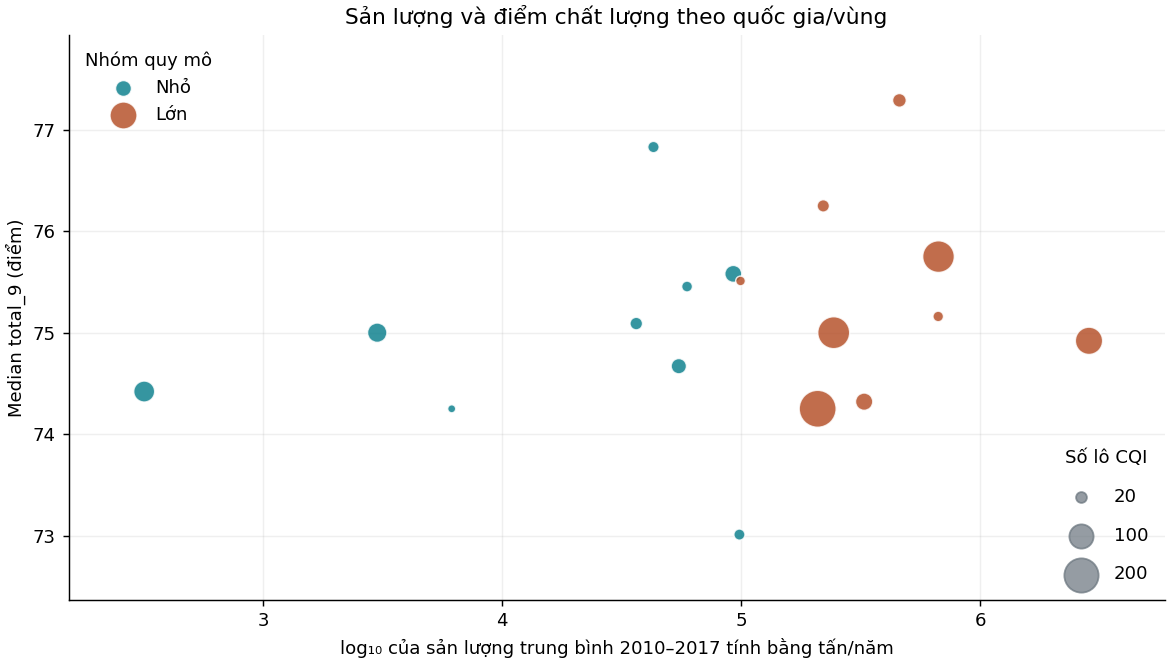

In [11]:
import matplotlib.pyplot as plt

mean_production_t = country_year_shares.groupby("country_fao")["production_t"].mean()
plot_countries = grouped_countries.join(mean_production_t.rename("mean_production_t"), validate="one_to_one")
if not plot_countries["mean_production_t"].fillna(0).gt(0).all():
    raise ValueError("Scatter log10 cần sản lượng trung bình dương cho từng vùng trong mẫu")

plot_countries["log_production"] = np.log10(plot_countries["mean_production_t"].to_numpy(dtype=float))
group_colors = {"Nhỏ": "#087E8B", "Lớn": "#B44D25"}
size_per_lot = 1.8

fig, ax = plt.subplots(figsize=(9, 5.1), layout="constrained")
for group, color in group_colors.items():
    points = plot_countries.loc[plot_countries["size_group"].eq(group)]
    ax.scatter(
        points["log_production"], points["median_total_9"],
        s=points["n_lots"] * size_per_lot, color=color, alpha=0.82,
        edgecolors="white", linewidths=0.8, label=group,
    )

group_legend = ax.legend(title="Nhóm quy mô", loc="upper left", frameon=False)
ax.add_artist(group_legend)
lot_handles = [
    ax.scatter([], [], s=n * size_per_lot, color="#68737C", alpha=0.7, label=str(n))
    for n in (20, 100, 200)
]
ax.legend(handles=lot_handles, title="Số lô CQI", loc="lower right", frameon=False, labelspacing=1.15)
ax.set(
    title="Sản lượng và điểm chất lượng theo quốc gia/vùng",
    xlabel="log₁₀ của sản lượng trung bình 2010–2017 tính bằng tấn/năm",
    ylabel="Median total_9 (điểm)",
)
ax.margins(x=0.08, y=0.15)
ax.set_axisbelow(True)
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### b. Chênh lệch median giữa hai nhóm quy mô

Biểu đồ này thể hiện trực tiếp ước lượng Nhỏ − Lớn và CI 95% đã tính bằng bootstrap. Điểm đánh dấu là chênh lệch quan sát, thanh ngang nối hai cận CI và đường dọc nét đứt tại 0 là mốc hai nhóm có cùng median.

Đọc dấu của điểm để biết hướng chênh lệch trong mẫu, rồi xem thanh CI nằm về một phía hay đi qua 0. Giá trị dưới 0 tương ứng với nhóm Nhỏ có điểm thấp hơn, còn trên 0 tương ứng với nhóm Nhỏ cao hơn. Biểu đồ hỗ trợ trả lời đồng thời chênh bao nhiêu điểm và dữ liệu cho phép chắc chắn đến đâu về hướng chênh lệch.

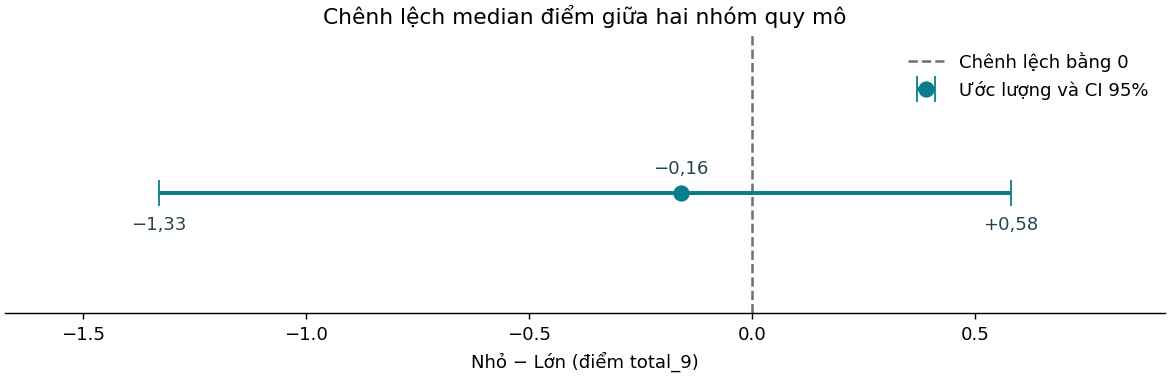

In [12]:
contrast = effects.loc["Chênh lệch median Nhỏ − Lớn"]
estimate = contrast["Ước lượng"]
low = contrast["Cận dưới CI 95%"]
high = contrast["Cận trên CI 95%"]

fig, ax = plt.subplots(figsize=(9, 2.9), layout="constrained")
ax.axvline(0, color="#68737C", linestyle="--", linewidth=1.4, label="Chênh lệch bằng 0")
ax.errorbar(
    estimate, 0, xerr=[[estimate - low], [high - estimate]],
    fmt="o", color="#087E8B", capsize=7, linewidth=2.2, markersize=8,
    label="Ước lượng và CI 95%",
)
for value, offset in [(low, -18), (estimate, 13), (high, -18)]:
    label = f"{value:+.2f}".replace(".", ",").replace("-", "−")
    ax.annotate(label, (value, 0), xytext=(0, offset), textcoords="offset points",
                ha="center", va="center", color="#254450")
padding = (max(high, 0) - min(low, 0)) * 0.18
ax.set(
    title="Chênh lệch median điểm giữa hai nhóm quy mô",
    xlabel="Nhỏ − Lớn (điểm total_9)",
    xlim=(min(low, 0) - padding, max(high, 0) + padding),
    ylim=(-0.42, 0.55),
    yticks=[],
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="upper right", frameon=False)
plt.show()

Bảng dưới tổng hợp hai kết quả chính để đối chiếu với phần trả lời. Mỗi dòng có tên thống kê, đơn vị, ước lượng, hai cận CI 95% và số vùng phân tích. Dòng chênh lệch median trả lời phép so sánh hai nhóm quy mô; dòng Spearman trả lời mức liên hệ khi xét tỷ trọng sản lượng của từng vùng. Cần đọc hai cận CI cùng ước lượng để thể hiện độ bất định.

In [13]:
results_table = effects.assign(**{"Số quốc gia/vùng": len(grouped_countries)})
display(results_table.reset_index().round(4))

,Thống kê,Đơn vị,Ước lượng,Cận dưới CI 95%,Cận trên CI 95%,Số quốc gia/vùng
0,Chênh lệch median Nhỏ − Lớn,điểm,-0.1600,-1.3300,0.5800,18
1,Spearman,hệ số,0.2273,-0.2271,0.5863,18


### c. Trả lời câu hỏi nghiên cứu

**Chênh lệch điểm giữa nhóm sản xuất nhỏ và lớn**

Trong mẫu phân tích, nhóm nhỏ có điểm trung vị ở cấp quốc gia thấp hơn nhóm lớn **0,16 điểm**. Trung vị của 9 điểm trung vị theo quốc gia là **75,00 điểm** ở nhóm nhỏ và **75,16 điểm** ở nhóm lớn. Khoảng tin cậy 95% của chênh lệch giữa nhỏ và lớn trải từ **−1,33 đến +0,58 điểm**. Vì khoảng này chứa 0 và trải từ âm sang dương nên dữ liệu chưa đủ để kết luận nhóm nào có điểm cao hơn.

Scatter plot cho thấy 7 trong 9 quốc gia hoặc vùng của mỗi nhóm có điểm trung vị từ 74 đến 76. Các điểm của hai nhóm chồng lấn trong khoảng này dù quy mô sản xuất khác nhau.

**Mức liên hệ giữa tỷ trọng sản lượng thế giới và điểm chất lượng**

Trên **18 quốc gia và vùng lãnh thổ** trong mẫu, hệ số tương quan Spearman giữa tỷ trọng sản lượng cà phê nhân xanh thế giới trung bình giai đoạn 2010–2017 và điểm `total_9` trung vị của các lô Arabica là **0,2273**. Các vùng có tỷ trọng sản lượng cao hơn có xu hướng xếp hạng cao hơn về điểm trung vị, nhưng xu hướng này yếu trong mẫu. Khoảng tin cậy 95% trải từ **−0,2271 đến 0,5863**. Khoảng này chứa cả giá trị âm, 0 và giá trị dương, nên dữ liệu chưa đủ để khẳng định chiều liên hệ.

Vì cả hai khoảng tin cậy đều chứa 0, kết quả từ mẫu CQI này chưa đủ để nhà rang xay dùng riêng quy mô sản xuất làm căn cứ ưu tiên quốc gia khi tìm nguồn Arabica có điểm chất lượng cao.